# Phase 2: Evaluation on the Test Set
**Project:** *Lead I or Twelve? Measuring How Much Heart-Disease Signal Survives a Wearable-Style Single-Lead ECG*

Every model is scored by the same code, `evaluate.py`, which is checked by `test_evaluate.py` (run `pytest test_evaluate.py`). This notebook scores the six frozen Phase 1 baselines. The CNN will go through the same functions in Phase 4.

**The protocol:**
1. **Cutoff:** chosen on the **black-box** set so that at least 95% of normal recordings are left alone (95% specificity).
2. **Decision rule:** a recording is flagged abnormal when *p > cutoff*. The cutoff is never re-tuned on test.
3. **Test metrics:**
   * AUROC and AUPRC, which cover every possible cutoff;
   * sensitivity and specificity at the fixed cutoff;
   * macro F1;
   * **per-category recall:** what fraction of the test recordings carrying MI (and likewise STTC, CD, HYP) get flagged.
4. **95% confidence intervals:** 1,000 bootstrap resamples of test **patients**, not recordings, because one patient's recordings are correlated. Every model uses the *same* resamples, so differences between lead sets are compared on identical data (**paired** differences).

> **The test set is used once.** These baselines are frozen. Nothing in Phase 1 may be re-tuned because of what this notebook shows.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score
from common import load_labels, load_predictions, ABN, CONFIGS, RESULTS_DIR
from evaluate import evaluate, paired_difference, bootstrap_indices, fmt_ci, TARGET_SPECIFICITY

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
N_BOOT, SEED = 1000, 0

CFG_COL = {"A_12lead": "#2a78d6", "B_limb": "#1baf7a", "C_leadI": "#eb6834"}
CFG_LABEL = {"A_12lead": "A · 12 leads", "B_limb": "B · 6 limb leads", "C_leadI": "C · Lead I"}
MODEL_LABEL = {"logreg": "Logistic regression", "gbt": "Gradient-boosted trees"}
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True, "axes.titleweight": "bold", "figure.dpi": 110})

## 1. Load labels, split and predictions

In [2]:
df = load_labels()
bb, te = (df.split == "blackbox").values, (df.split == "test").values
y = df.abnormal.values
cats_test = {c: df[c].values[te] == 1 for c in ABN}

MODELS = ["logreg", "gbt"]
probs = {(m, cfg): load_predictions(f"baseline_{m}_{cfg}", df).values for m in MODELS for cfg in CONFIGS}

# sanity check: black-box AUROC must match what Phase 1 reported
bb_auc = pd.DataFrame({cfg: {m: roc_auc_score(y[bb], probs[m, cfg][bb]) for m in MODELS} for cfg in CONFIGS})
print("Black-box AUROC (should match Phase 1):"); print(bb_auc.round(3))
assert abs(bb_auc.loc["gbt", "A_12lead"] - 0.927) < 0.001

print(f"\nTest set: {te.sum():,} recordings from {df.patient_id[te].nunique():,} patients")
print("Abnormal recordings per category in test:", {c: int(m.sum()) for c, m in cats_test.items()})

# one shared set of patient-level bootstrap resamples, so every comparison is paired
boot = bootstrap_indices(df.patient_id.values[te], N_BOOT, SEED)

Black-box AUROC (should match Phase 1):
        A_12lead  B_limb  C_leadI
logreg     0.886   0.873    0.813
gbt        0.927   0.904    0.845

Test set: 3,207 recordings from 2,791 patients
Abnormal recordings per category in test: {'MI': 819, 'STTC': 787, 'CD': 735, 'HYP': 396}


## 2. Overall test metrics (95% CI)

In [3]:
results = {}
for m in MODELS:
    for cfg in CONFIGS:
        p = probs[m, cfg]
        results[m, cfg] = evaluate(y[bb], p[bb], y[te], p[te], cats_test, boot=boot)

long = pd.concat({k: pd.DataFrame({"point": r["point"], "ci_low": r["ci_low"], "ci_high": r["ci_high"]})
                  for k, r in results.items()}, names=["model", "config", "metric"]).reset_index()
long.to_csv(os.path.join(RESULTS_DIR, "test_metrics_baselines.csv"), index=False)

def table(metrics, pct):
    rows = {}
    for (m, cfg), r in results.items():
        rows[(MODEL_LABEL[m], CFG_LABEL[cfg])] = {k: fmt_ci(r["point"][k], r["ci_low"][k], r["ci_high"][k], pct=pct)
                                                  for k in metrics}
    return pd.DataFrame(rows).T

print("Cutoffs (from black-box set):", {f"{m}/{cfg}": round(r["cutoff"], 3) for (m, cfg), r in results.items()})
table(["AUROC", "AUPRC", "macro_F1"], pct=False).join(table(["sensitivity", "specificity"], pct=True))

Cutoffs (from black-box set): {'logreg/A_12lead': 0.727, 'logreg/B_limb': 0.706, 'logreg/C_leadI': 0.693, 'gbt/A_12lead': 0.719, 'gbt/B_limb': 0.743, 'gbt/C_leadI': 0.716}


AUROC  \
Logistic regression    A · 12 leads      0.896 [0.885, 0.907]   
                       B · 6 limb leads  0.877 [0.865, 0.890]   
                       C · Lead I        0.822 [0.806, 0.835]   
Gradient-boosted trees A · 12 leads      0.935 [0.927, 0.944]   
                       B · 6 limb leads  0.906 [0.895, 0.916]   
                       C · Lead I        0.852 [0.837, 0.864]   

                                                        AUPRC  \
Logistic regression    A · 12 leads      0.931 [0.923, 0.940]   
                       B · 6 limb leads  0.917 [0.907, 0.927]   
                       C · Lead I        0.878 [0.865, 0.891]   
Gradient-boosted trees A · 12 leads      0.957 [0.951, 0.964]   
                       B · 6 limb leads  0.940 [0.931, 0.947]   
                       C · Lead I        0.903 [0.891, 0.913]   

                                                     macro_F1  \
Logistic regression    A · 12 leads      0.762 [0.746, 0.779]   
                       B · 6 limb leads  0.742 [0.726, 0.759]   
                       C · Lead I        0.672 [0.654, 0.688]   
Gradient-boosted trees A · 12 leads      0.839 [0.826, 0.853]   
                       B · 6 limb leads  0.791 [0.776, 0.806]   
                       C · Lead I        0.732 [0.715, 0.748]   

                                                sensitivity  \
Logistic regression    A · 12 leads      61.3% [58.8, 63.7]   
                       B · 6 limb leads  58.8% [56.3, 61.3]   
                       C · Lead I        47.8% [45.1, 50.1]   
Gradient-boosted trees A · 12 leads      75.7% [73.8, 77.9]   
                       B · 6 limb leads  65.9% [63.5, 68.3]   
                       C · Lead I        56.7% [54.0, 59.1]   

                                                specificity  
Logistic regression    A · 12 leads      96.5% [95.5, 97.5]  
                       B · 6 limb leads  95.4% [94.4, 96.5]  
                       C · Lead I        94.8% [93.5, 96.0]  
Gradient-boosted trees A · 12 leads      94.9% [93.7, 96.1]  
                       B · 6 limb leads  97.0% [96.1, 97.8]  
                       C · Lead I        96.0% [94.9, 97.1]

## 3. Per-category recall: which categories account for the loss?
This is the second half of the research question. At the 95%-specificity cutoff, we ask what fraction of the test recordings carrying each category get flagged abnormal.

In [4]:
table([f"recall_{c}" for c in ABN], pct=True).rename(columns=lambda c: c.replace("recall_", ""))

MI  \
Logistic regression    A · 12 leads      66.4% [62.8, 69.9]   
                       B · 6 limb leads  64.6% [61.0, 68.0]   
                       C · Lead I        48.6% [44.9, 52.0]   
Gradient-boosted trees A · 12 leads      81.4% [78.7, 84.0]   
                       B · 6 limb leads  71.1% [67.6, 74.3]   
                       C · Lead I        58.0% [54.3, 61.5]   

                                                       STTC  \
Logistic regression    A · 12 leads      67.7% [64.1, 71.2]   
                       B · 6 limb leads  64.2% [60.7, 67.9]   
                       C · Lead I        62.0% [58.5, 65.3]   
Gradient-boosted trees A · 12 leads      84.9% [82.2, 87.6]   
                       B · 6 limb leads  74.3% [71.0, 77.6]   
                       C · Lead I        70.5% [67.0, 73.8]   

                                                         CD  \
Logistic regression    A · 12 leads      69.8% [66.3, 73.5]   
                       B · 6 limb leads  67.1% [63.5, 71.0]   
                       C · Lead I        49.0% [45.1, 52.7]   
Gradient-boosted trees A · 12 leads      76.1% [72.8, 79.4]   
                       B · 6 limb leads  71.2% [67.7, 74.7]   
                       C · Lead I        58.4% [54.8, 62.0]   

                                                        HYP  
Logistic regression    A · 12 leads      77.5% [73.4, 81.9]  
                       B · 6 limb leads  71.0% [66.3, 75.8]  
                       C · Lead I        67.9% [63.2, 72.9]  
Gradient-boosted trees A · 12 leads      83.8% [80.1, 87.6]  
                       B · 6 limb leads  75.3% [70.7, 79.9]  
                       C · Lead I        73.2% [68.6, 78.0]

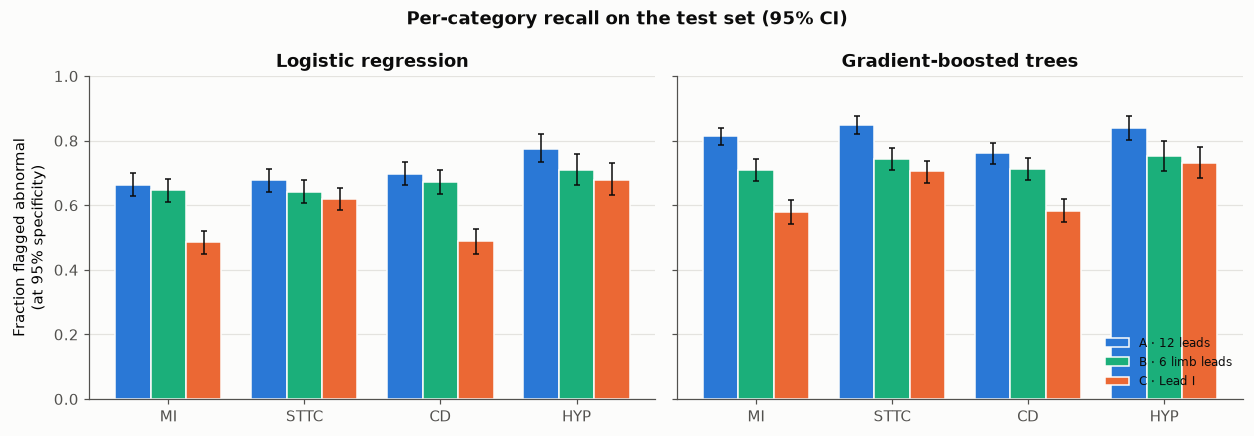

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4), sharey=True)
x, w = np.arange(len(ABN)), 0.26
for ax, m in zip(axes, MODELS):
    for j, cfg in enumerate(CONFIGS):
        r = results[m, cfg]
        k = [f"recall_{c}" for c in ABN]
        pt, lo, hi = r["point"][k].values, r["ci_low"][k].values, r["ci_high"][k].values
        ax.bar(x + (j - 1) * w, pt, w, color=CFG_COL[cfg], label=CFG_LABEL[cfg], edgecolor=SURF)
        ax.errorbar(x + (j - 1) * w, pt, yerr=[pt - lo, hi - pt], fmt="none", ecolor=INK, elinewidth=1, capsize=2)
    ax.set_xticks(x, ABN); ax.set_ylim(0, 1); ax.set_title(MODEL_LABEL[m]); ax.grid(axis="x", visible=False)
axes[0].set_ylabel(f"Fraction flagged abnormal\n(at {TARGET_SPECIFICITY:.0%} specificity)")
axes[1].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Per-category recall on the test set (95% CI)", fontweight="bold")
plt.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "fig2_per_category_recall_baselines.png"), dpi=200); plt.show()

## 4. How much is lost when leads are removed? Paired differences
For each model: metric(12 leads) − metric(fewer leads), computed on the same bootstrap resamples. A positive delta means the 12-lead model is better. **Significant** means the 95% CI excludes 0.

In [6]:
COMPARISONS = [("A_12lead", "B_limb"), ("A_12lead", "C_leadI"), ("B_limb", "C_leadI")]
KEEP = ["AUROC", "sensitivity"] + [f"recall_{c}" for c in ABN]
diffs = {}
for m in MODELS:
    for a, b in COMPARISONS:
        d = paired_difference(y[bb], probs[m, a][bb], probs[m, b][bb], y[te], probs[m, a][te], probs[m, b][te],
                              cats_test, boot)
        diffs[m, f"{a[0]} − {b[0]}"] = d.loc[KEEP]
diff_long = pd.concat(diffs, names=["model", "comparison", "metric"]).reset_index()
diff_long.to_csv(os.path.join(RESULTS_DIR, "test_paired_differences_baselines.csv"), index=False)

show = diff_long.copy()
show["delta [95% CI]"] = [f"{d:+.3f} [{l:+.3f}, {h:+.3f}]" + (" *" if s else "")
                          for d, l, h, s in zip(show.delta, show.ci_low, show.ci_high, show.significant)]
show.pivot_table(index=["model", "comparison"], columns="metric", values="delta [95% CI]", aggfunc="first",
                 sort=False)[KEEP]

metric                                 AUROC                sensitivity  \
model  comparison                                                         
logreg A − B       +0.019 [+0.012, +0.025] *  +0.025 [+0.009, +0.040] *   
       A − C       +0.074 [+0.063, +0.087] *  +0.135 [+0.113, +0.157] *   
       B − C       +0.056 [+0.046, +0.066] *  +0.110 [+0.090, +0.134] *   
gbt    A − B       +0.030 [+0.022, +0.037] *  +0.098 [+0.081, +0.114] *   
       A − C       +0.084 [+0.073, +0.096] *  +0.191 [+0.168, +0.215] *   
       B − C       +0.054 [+0.045, +0.065] *  +0.093 [+0.071, +0.115] *   

metric                             recall_MI                recall_STTC  \
model  comparison                                                         
logreg A − B         +0.018 [-0.005, +0.045]  +0.036 [+0.010, +0.061] *   
       A − C       +0.178 [+0.146, +0.213] *  +0.057 [+0.028, +0.088] *   
       B − C       +0.160 [+0.129, +0.191] *    +0.022 [-0.007, +0.053]   
gbt    A − B       +0.104 [+0.080, +0.130] *  +0.105 [+0.078, +0.131] *   
       A − C       +0.234 [+0.202, +0.270] *  +0.144 [+0.111, +0.177] *   
       B − C       +0.131 [+0.100, +0.163] *  +0.038 [+0.011, +0.068] *   

metric                             recall_CD                 recall_HYP  
model  comparison                                                        
logreg A − B       +0.027 [+0.003, +0.052] *  +0.066 [+0.033, +0.098] *  
       A − C       +0.208 [+0.175, +0.244] *  +0.096 [+0.060, +0.136] *  
       B − C       +0.181 [+0.146, +0.218] *    +0.030 [-0.005, +0.067]  
gbt    A − B       +0.049 [+0.028, +0.068] *  +0.086 [+0.057, +0.115] *  
       A − C       +0.177 [+0.145, +0.209] *  +0.106 [+0.071, +0.145] *  
       B − C       +0.128 [+0.098, +0.161] *    +0.020 [-0.015, +0.059]

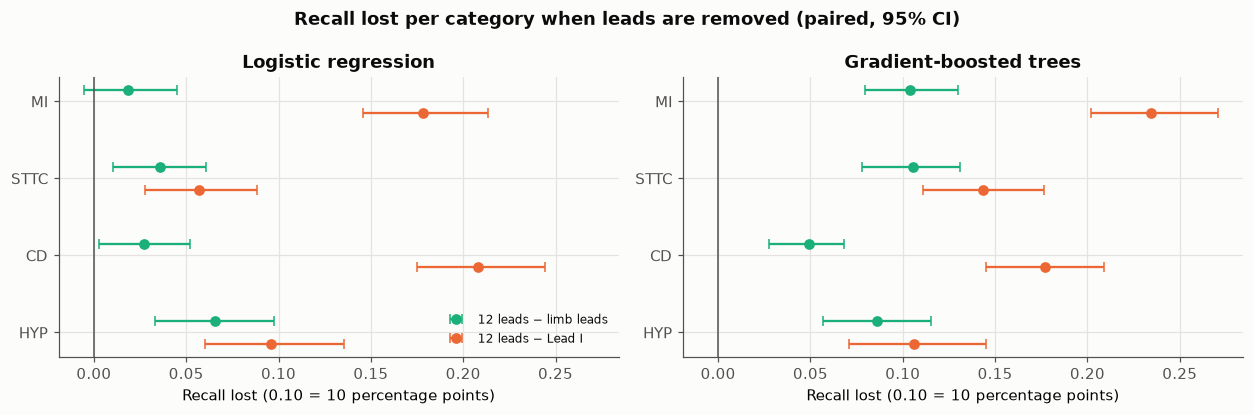

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), sharex=True)
cats = [f"recall_{c}" for c in ABN]
for ax, m in zip(axes, MODELS):
    for j, (comp, col) in enumerate([("A − B", CFG_COL["B_limb"]), ("A − C", CFG_COL["C_leadI"])]):
        d = diffs[m, comp].loc[cats]
        ypos = np.arange(len(cats)) + (j - 0.5) * 0.3
        ax.errorbar(d.delta, ypos, xerr=[d.delta - d.ci_low, d.ci_high - d.delta], fmt="o", color=col,
                    capsize=3, label=f"12 leads − {'limb leads' if comp == 'A − B' else 'Lead I'}")
    ax.axvline(0, color=INK2, lw=1)
    ax.set_yticks(np.arange(len(cats)), ABN); ax.invert_yaxis(); ax.set_title(MODEL_LABEL[m])
    ax.set_xlabel("Recall lost (0.10 = 10 percentage points)")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Recall lost per category when leads are removed (paired, 95% CI)", fontweight="bold")
plt.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "fig_recall_loss_baselines.png"), dpi=200); plt.show()

## 5. ROC and precision-recall curves (test set)
Gradient-boosted trees are drawn solid and logistic regression dashed. In Phase 4 the CNN will take the solid lines and the best baseline will move to dashed.

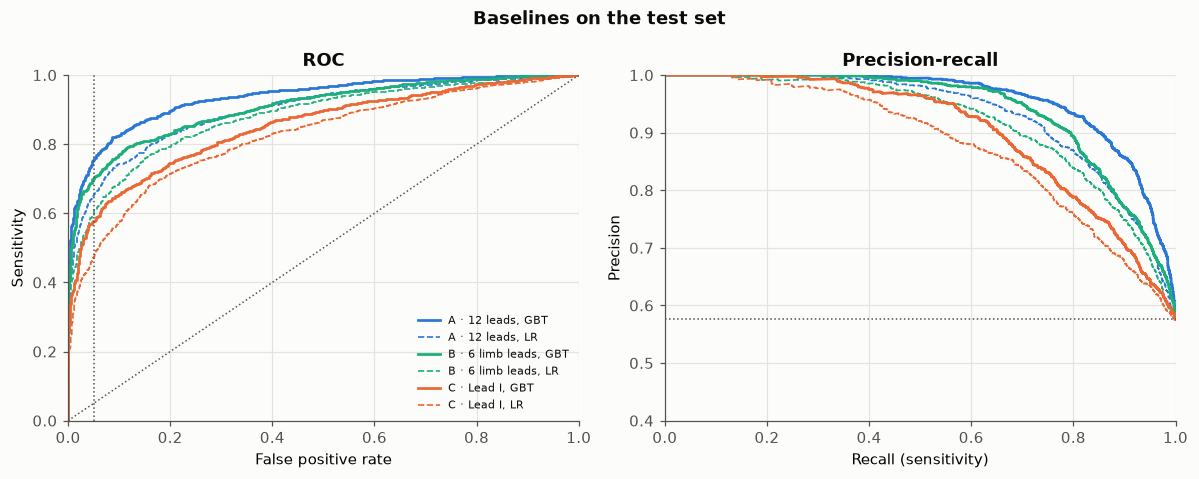

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for cfg in CONFIGS:
    for m, ls in [("gbt", "-"), ("logreg", "--")]:
        p = probs[m, cfg][te]
        fpr, tpr, _ = roc_curve(y[te], p)
        prec, rec, _ = precision_recall_curve(y[te], p)
        lab = f"{CFG_LABEL[cfg]}, {'GBT' if m == 'gbt' else 'LR'}"
        axes[0].plot(fpr, tpr, ls, color=CFG_COL[cfg], lw=1.8 if m == "gbt" else 1.1, label=lab)
        axes[1].plot(rec, prec, ls, color=CFG_COL[cfg], lw=1.8 if m == "gbt" else 1.1, label=lab)
axes[0].plot([0, 1], [0, 1], ":", color=INK2, lw=1)
axes[0].axvline(1 - TARGET_SPECIFICITY, color=INK2, lw=1, ls=":")
axes[0].set(title="ROC", xlabel="False positive rate", ylabel="Sensitivity", xlim=(0, 1), ylim=(0, 1))
axes[1].axhline(y[te].mean(), color=INK2, lw=1, ls=":")
axes[1].set(title="Precision-recall", xlabel="Recall (sensitivity)", ylabel="Precision", xlim=(0, 1), ylim=(0.4, 1))
axes[0].legend(frameon=False, fontsize=7, loc="lower right")
fig.suptitle("Baselines on the test set", fontweight="bold")
plt.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "fig1_roc_pr_baselines.png"), dpi=200); plt.show()

## 6. Confusion matrices (test set, at the black-box cutoff)

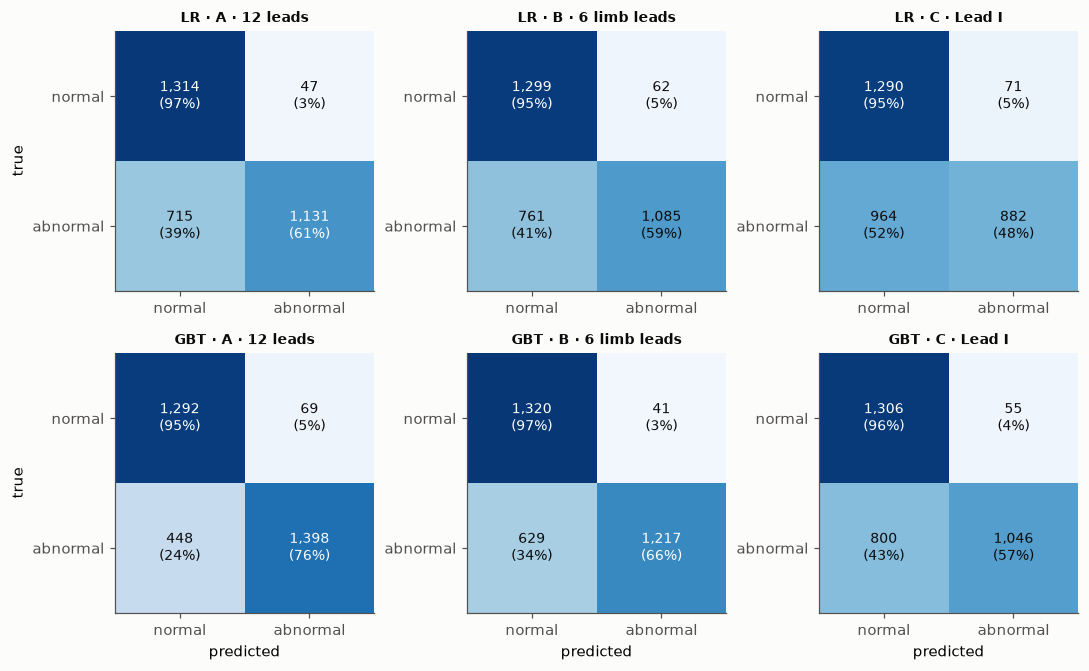

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6.2))
for i, m in enumerate(MODELS):
    for j, cfg in enumerate(CONFIGS):
        ax, cm = axes[i, j], results[m, cfg]["confusion"]
        ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
        for (r, c), v in np.ndenumerate(cm):
            frac = v / cm[r].sum()
            ax.text(c, r, f"{v:,}\n({frac:.0%})", ha="center", va="center", fontsize=9,
                    color="white" if frac > 0.6 else INK)
        ax.set_xticks([0, 1], ["normal", "abnormal"]); ax.set_yticks([0, 1], ["normal", "abnormal"])
        ax.grid(False); ax.set_title(f"{'GBT' if m == 'gbt' else 'LR'} · {CFG_LABEL[cfg]}", fontsize=9)
        if j == 0: ax.set_ylabel("true")
        if i == 1: ax.set_xlabel("predicted")
plt.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "fig_confusion_baselines.png"), dpi=200); plt.show()

## 7. What we observed

**1. Every removal of leads costs performance, and every gap is statistically significant.** These are gradient-boosted trees, the stronger baseline, on the test set:

| | AUROC | sensitivity at the black-box cutoff |
|---|---|---|
| A · 12 leads | 0.935 [0.927, 0.944] | 75.7% |
| B · 6 limb leads | 0.906 [0.895, 0.916] | 65.9% |
| C · Lead I | 0.852 [0.837, 0.864] | 56.7% |

At the same false-alarm budget, the Lead-I model catches about **19 points fewer** abnormal recordings: roughly 1 in 4 of the abnormal ECGs the 12-lead model would catch. AUROC alone (0.935 vs 0.852) makes the loss look smaller than it is in screening terms, which supports the motivation behind the proposal.

**2. Which categories account for the loss (trees, 12 leads − Lead I, recall points):** MI −23.4 [20.2, 27.0] > CD −17.7 > STTC −14.4 > HYP −10.6.
* **MI loses the most, as hypothesized.**
* **HYP loses the *least*.** That contradicts the hypothesis. Possible reasons: HYP rarely occurs alone (it's often flagged through a co-occurring label), and HYP is the smallest category, so its confidence intervals are the widest.
* **CD loses a lot.** That also contradicts the hypothesis, which expected conduction problems to be visible from any lead. With logistic regression, CD even loses the most (−20.8). This matches the literature in `RESEARCH_NOTES.md`: incomplete RBBB and left fascicular block depend on V1's shape or on the heart's axis, and Lead I alone shows neither.

**3. Where the loss happens is the surprise.** For MI and CD, most of the recall is lost in the step from **limb leads to Lead I** (B − C), not from dropping the chest leads (A − B). With logistic regression, the A − B gap for MI isn't even significant (+1.8 [−0.5, +4.5]). Inferior MI shows in II, III and aVF, and the heart's axis needs two limb leads, so a second limb lead may matter as much as the chest leads. This suggests a refinement for the slides: *"the precordial leads matter for STTC and HYP; the other limb leads matter for MI and CD."*

**4. Caveats to state honestly:**
* These are baselines on hand-made features. The CNN may use the chest leads very differently, so Phase 4 decides the main answer.
* Each model's cutoff is fixed on the black-box set, so test specificity varies from 94.8% to 97.0%. For example, the tree B model ran at 97.0%, which slightly understates its sensitivity and inflates the A − B gap.
* This test split doesn't have the extra label review that PTB-XL's official test fold had (see DECISIONS D4).
* MI and CD weren't broken down into subtypes (for example inferior vs anterior MI). That's an open question (DECISIONS Q5).